In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize

from sklearn.metrics import roc_curve, auc
from scipy.stats import norm
sys.path.append("../")

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 9
plt.rcParams["pdf.fonttype"] = 42  # embed TrueType instead of Type 3 fonts

## Distribution

Normal: Mean = -0.1161, Std = 0.9311
Barrage: Mean = 1.6540, Std = 0.5917
Deceptive: Mean = 1.6551, Std = 1.1863
Pilot: Mean = 1.4252, Std = 1.0428
Random_hop: Mean = 3.0975, Std = 1.3274
Sweep: Mean = 3.0317, Std = 1.1234


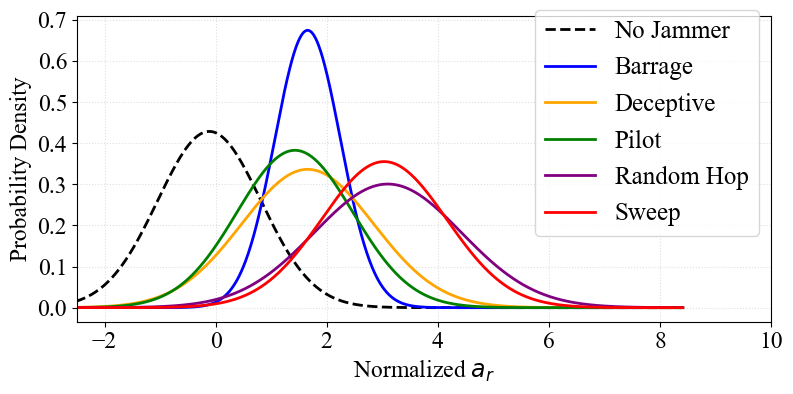

In [2]:
# Define five score files
score_files = {
    "Normal": "../Anomaly_Scores/barrage/Scores_Unsupervised_model.npy",
    "Barrage": "../Anomaly_Scores/barrage/Scores_Unsupervised_model.npy",
    "Deceptive": "../Anomaly_Scores/deceptive/Scores_Unsupervised_model.npy",
    "Pilot": "../Anomaly_Scores/pilot/Scores_Unsupervised_model.npy",
    "Random_hop": "../Anomaly_Scores/random_hop/Scores_Unsupervised_model.npy",
    "Sweep": "../Anomaly_Scores/sweep/Scores_Unsupervised_model.npy"
}

label_files = {
    "Normal": "../Anomaly_Scores/barrage/Labels_Unsupervised.npy",
    "Barrage": "../Anomaly_Scores/barrage/Labels_Unsupervised.npy",
    "Deceptive": "../Anomaly_Scores/deceptive/Labels_Unsupervised.npy",
    "Pilot": "../Anomaly_Scores/pilot/Labels_Unsupervised.npy",
    "Random_hop": "../Anomaly_Scores/random_hop/Labels_Unsupervised.npy",
    "Sweep": "../Anomaly_Scores/sweep/Labels_Unsupervised.npy"
}


# Colors for the five distributions
colors = ["k", "blue", "orange", "green", "purple", "red"]

# Load scores and fit normal distributions
fitted_distributions = {}

for (name, score_path), (_, label_path) in zip(score_files.items(), label_files.items()):
    
    scores_m = np.load(score_path).ravel()
    labels = np.load(label_path).ravel()

    mask = labels == name
    scores = scores_m[mask]
    scores = scores[np.isfinite(scores)]

    # Fit normal distribution
    mu, sigma = norm.fit(scores)

    fitted_distributions[name] = (mu, sigma)

    print(f"{name}: Mean = {mu:.4f}, Std = {sigma:.4f}")

# Common x-axis range for all distributions
x_min = min(
    mu - 4 * sigma
    for mu, sigma in fitted_distributions.values()
)

x_max = max(
    mu + 4 * sigma
    for mu, sigma in fitted_distributions.values()
)

x = np.linspace(x_min, x_max, 1000)

# Plot all five fitted distributions
plt.figure(figsize=(8, 4))

for (name, (mu, sigma)), color in zip(
    fitted_distributions.items(), colors
):

    pdf = norm.pdf(x, loc=mu, scale=sigma)

    if name == 'Normal':
        plt.plot(
            x,
            pdf,
            linestyle='--',
            color=color,
            linewidth=2,
            label='No Jammer'
        )
    else:
        plt.plot(
            x,
            pdf,
            color=color,
            linewidth=2,
            label=name.replace("_", " ").title()
        )

# Plot formatting
plt.xlim(-2.5, 10)
plt.xlabel(r"Normalized $a_{r}$", fontsize=17)
plt.ylabel("Probability Density", fontsize=17)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)

plt.legend(
    loc="center right",
    bbox_to_anchor=(1, 0.65),
    fontsize=18,
    frameon=True,
    #edgecolor="black"
)

plt.grid(True, linestyle=":", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "../Figures/Score_Distributions.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Model Comparison

In [3]:
# Base directory
base_dir = "..\\Anomaly_Scores"

# Jammer names
jammers = ["barrage", "deceptive", "pilot", "random_hop", "sweep"]

# Models: (label file, score file)
models = {
    "Supervised (Including)": (
        "Labels_Supervised.npy",
        "Scores_Supervised_including_model.npy"
    ),
    "Supervised (Excluding)": (
        "Labels_Supervised.npy",
        "Scores_Supervised_excluding_model.npy"
    ),
    "Unsupervised": (
        "Labels_Unsupervised.npy",
        "Scores_Unsupervised_model.npy"
    )
}

# Colors for each model
colors = {
    "Supervised (Including)": "tab:blue",
    "Supervised (Excluding)": "tab:orange",
    "Unsupervised": "tab:green"
}

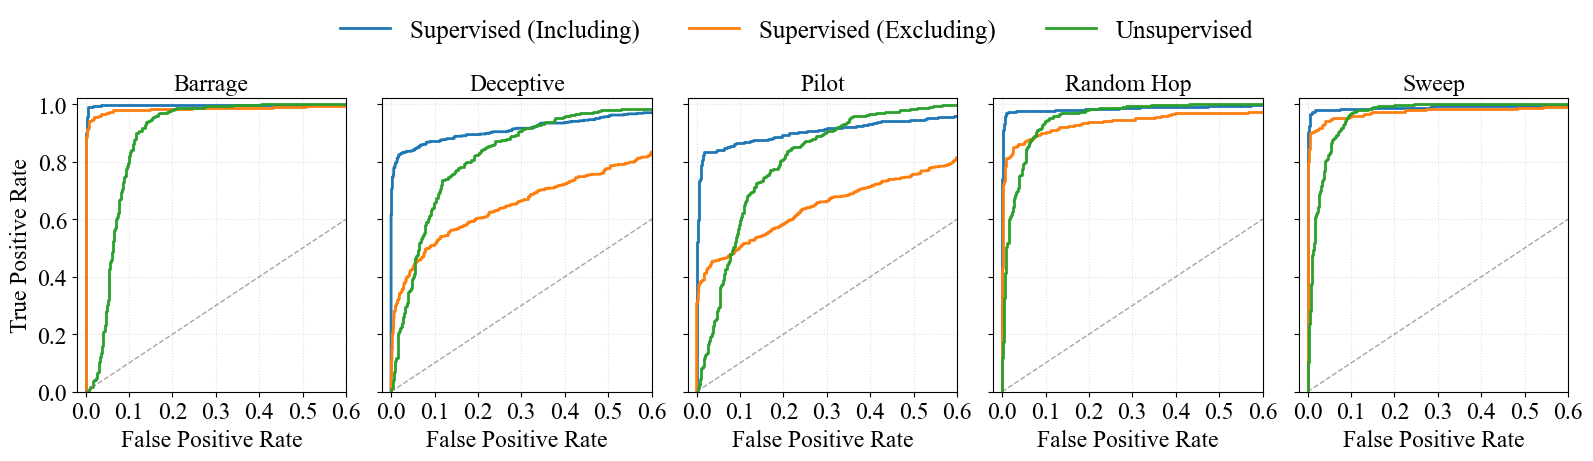

In [4]:
# Create 5 subplots in one row
fig, axes = plt.subplots(
    1, 5, figsize=(16, 4.5), sharex=True, sharey=True
)

for ax, jammer in zip(axes, jammers):

    jammer_dir = os.path.join(base_dir, jammer)

    for model_name, (label_file, score_file) in models.items():

        # Load labels and scores
        y_true = np.load(os.path.join(jammer_dir, label_file)).ravel()
        y_labels = (y_true != "Normal").astype(int)
        y_score = np.load(os.path.join(jammer_dir, score_file)).ravel()

        # Calculate ROC curve and AUC
        fpr, tpr, _ = roc_curve(y_labels, y_score)
        roc_auc = auc(fpr, tpr)

        # Plot ROC curve
        ax.plot(
            fpr,
            tpr,
            color=colors[model_name],
            linewidth=2,
            label=model_name
        )

    # Random classifier reference
    ax.plot(
        [0, 1], [0, 1],
        color="gray",
        linestyle="--",
        linewidth=1,
        alpha=0.7
    )

    # Subplot formatting
    ax.set_title(jammer.replace("_", " ").title(), fontsize=17)
    ax.set_xlabel("False Positive Rate", fontsize=17)
    ax.set_xlim(-0.02, 0.6)
    ax.set_xticks(np.arange(0.0, 0.61, 0.1))
    ax.tick_params(axis='x', labelsize=17)
    ax.set_ylim(0, 1.02)
    ax.grid(True, linestyle=":", alpha=0.4)

    # No individual subplot legends

axes[0].set_ylabel("True Positive Rate", fontsize=17)
axes[0].tick_params(axis='y', labelsize=17)

# Get legend handles and labels from the first subplot
handles, labels = axes[0].get_legend_handles_labels()

# Add one horizontal legend above all subplots
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=len(labels),
    fontsize=18,
    frameon=False
)

# Adjust layout to leave space for the shared legend
plt.tight_layout(rect=[0, 0, 1, 0.9])

# Save figure
plt.savefig(
    "../Figures/ROC_Comparison_Jammers.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Power

In [5]:
# Define five score files
score_files = {
    "Barrage": "../Anomaly_Scores/barrage/Scores_Unsupervised_model.npy",
    "Deceptive": "../Anomaly_Scores/deceptive/Scores_Unsupervised_model.npy",
    "Pilot": "../Anomaly_Scores/pilot/Scores_Unsupervised_model.npy",
    "Random_hop": "../Anomaly_Scores/random_hop/Scores_Unsupervised_model.npy",
    "Sweep": "../Anomaly_Scores/sweep/Scores_Unsupervised_model.npy"
}

power_files = {
    "Barrage": "../Anomaly_Scores/barrage/Powers.npy",
    "Deceptive": "../Anomaly_Scores/deceptive/Powers.npy",
    "Pilot": "../Anomaly_Scores/pilot/Powers.npy",
    "Random_hop": "../Anomaly_Scores/random_hop/Powers.npy",
    "Sweep": "../Anomaly_Scores/sweep/Powers.npy"
}

label_files = {
    "Barrage": "../Anomaly_Scores/barrage/Labels_Unsupervised.npy",
    "Deceptive": "../Anomaly_Scores/deceptive/Labels_Unsupervised.npy",
    "Pilot": "../Anomaly_Scores/pilot/Labels_Unsupervised.npy",
    "Random_hop": "../Anomaly_Scores/random_hop/Labels_Unsupervised.npy",
    "Sweep": "../Anomaly_Scores/sweep/Labels_Unsupervised.npy"
}

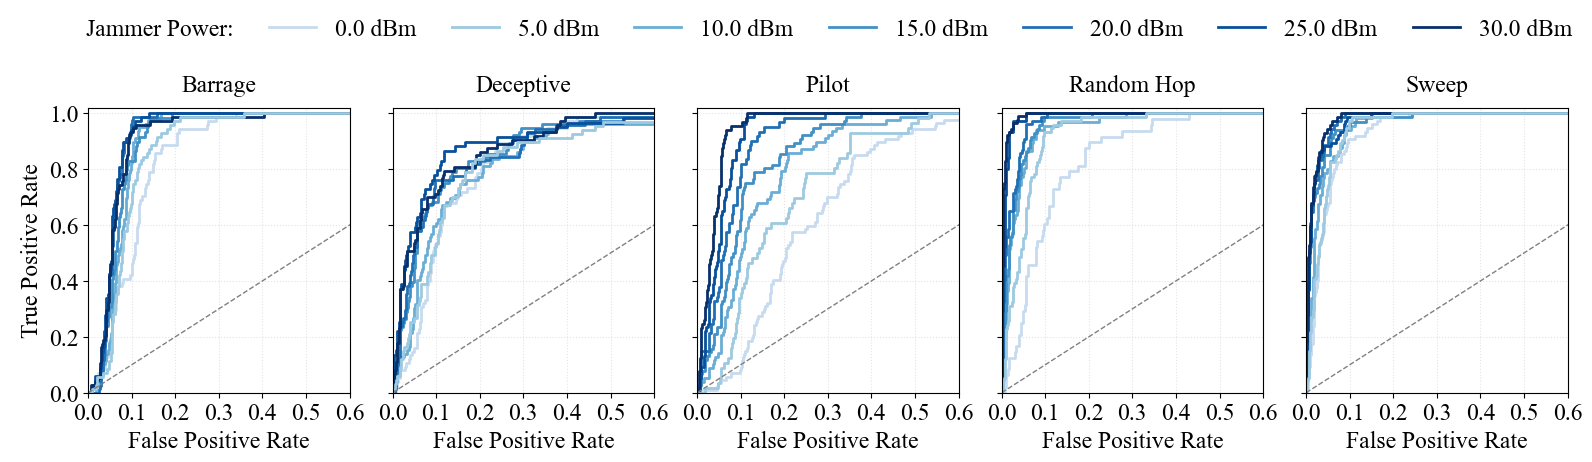

In [6]:
from matplotlib.lines import Line2D

# Create figure with five subplots
fig, axes = plt.subplots(
    1, 5,
    figsize=(16, 4.5),
    sharex=True,
    sharey=True
)

jammer_types = list(score_files.keys())

# Collect all power levels, excluding "No Jammer"
all_powers = np.unique(np.concatenate([
    np.load(power_files[jammer]).ravel()
    for jammer in jammer_types
]))

all_powers = all_powers[all_powers != "No Jammer"]

# Sort power levels numerically
all_powers = sorted(all_powers, key=lambda p: float(p))

# Assign lighter blue to lower powers and darker blue to higher powers
colors = cm.Blues(
    np.linspace(0.25, 1.0, len(all_powers))
)

power_colors = dict(zip(all_powers, colors))

for ax, jammer in zip(axes, jammer_types):

    scores = np.load(score_files[jammer]).ravel()
    powers = np.load(power_files[jammer]).ravel()
    j_labels = np.load(label_files[jammer]).ravel()

    labels = (j_labels == jammer)

    if not (len(scores) == len(powers) == len(labels)):
        raise ValueError(f"Array lengths do not match for {jammer}")

    unique_powers = np.sort(np.unique(powers[powers != "No Jammer"]))


    for power in unique_powers:

        mask = (labels == 0) | (
            (labels == 1) & (powers == power)
        )

        y_true = labels[mask]
        y_score = scores[mask]

        if len(np.unique(y_true)) < 2:
            continue

        fpr, tpr, _ = roc_curve(y_true, y_score)

        ax.plot(
            fpr,
            tpr,
            color=power_colors[power],
            linewidth=2
        )

    # Random classifier reference
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        linewidth=1
    )

    # Jammer name as subplot title
    ax.set_title(
        jammer.replace("_", " ").title(),
        fontsize=17,
        pad=12
    )

    ax.set_xlim([0.0, 0.6])
    ax.set_xticks(np.arange(0.0,0.61,0.1))
    ax.set_ylim([0, 1.02])

    ax.grid(True, linestyle=":", alpha=0.35)
    ax.tick_params(axis="both", labelsize=17)
    ax.set_xlabel("False Positive Rate", fontsize=17)

axes[0].set_ylabel("True Positive Rate", fontsize=17)
axes[0].tick_params(axis='y', labelsize=17)

# Create one shared legend for the entire figure
legend_handles = [
    Line2D(
        [0], [0],
        color=power_colors[power],
        linewidth=2,
        label=f"{power} dBm"
    )
    for power in all_powers
]


legend_title_handle = Line2D([], [], linestyle="none", label="Jammer Power:")

fig.legend(
    handles=[legend_title_handle] + legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=len(labels) + 1,
    fontsize=17,
    frameon=False,
    columnspacing=1.5,
    handlelength=2
)
plt.subplots_adjust(
    left=0.06,
    right=0.99,
    bottom=0.16,
    top=0.78,
    wspace=0.12
)

plt.tight_layout(rect=[0, 0, 1, 0.9])

plt.savefig(
    "../Figures/ROC_Jammer_Power.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()